## Table of Contents
- 1. Multi-Index DF & Hierarchical Slicing.
- 2. Vectorized strings & regex operations
- 3. Transform pipelines
- 4. memory optimization and data type downcasting
high performance query

In [1]:
# Global imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Global imports applied successfully.")

Global imports applied successfully.


In [2]:

# Visualization settings
sns.set_theme(style="whitegrid",palette="muted")
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.dpi'] = 120
print("Visualization settings applied successfully.")

Visualization settings applied successfully.


## 1. Multi-Index DataFrames & Hierarchical Slicing

multi-indexed series
 Region  Year
North   2024    100
        2025    150
South   2024    200
        2025    250
dtype: int64
____________________________________________________________
North region sales
 Year
2024    100
2025    150
dtype: int64


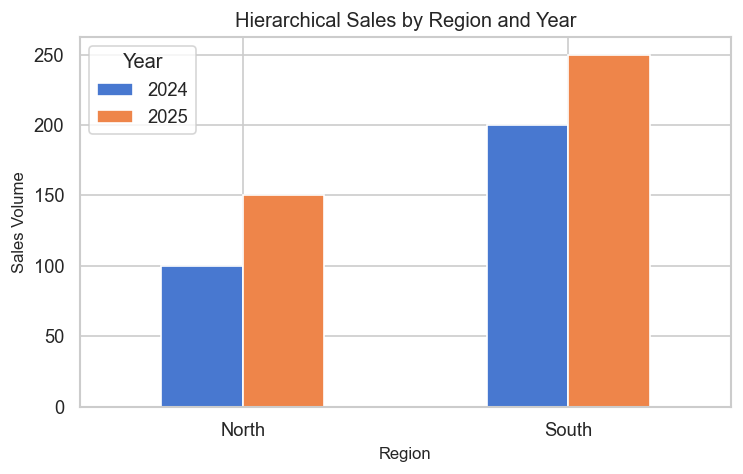

In [4]:
arrays = [['North','North','South','South'],[2024,2025,2024,2025]]
sales =[100, 150, 200, 250]
# create a multi-index from arrays
index = pd.MultiIndex.from_arrays(arrays, names=('Region', 'Year'))

my_sales_region_wise = pd.Series(sales, index=index)
print("multi-indexed series\n",my_sales_region_wise)
print("_" * 60)
# hierarchical indexing
print("North region sales\n", my_sales_region_wise.loc['North'])
# print("_" * 60)
# print("North region sales[0]", my_sales_region_wise.iloc[0],sep="\t:\t")
# print("North region sales[0:1]", my_sales_region_wise.iloc[0:1],sep="\n")
# print("_" * 60)

df_plot = my_sales_region_wise.unstack(level='Year')
# print("unstacked DataFrame\n", df_plot)
# visualization
ax = df_plot.plot(kind='bar',figsize=(7,4))
plt.title('Hierarchical Sales by Region and Year')
plt.xlabel('Region')
plt.ylabel('Sales Volume')
plt.xticks(rotation=0)
plt.show()

## 2. Vectorized strings & regex operations

In [5]:
data = {'address': ['100 Main St, Suite 400, NY 10001', '456 Market Rd, CA 90210', '789 Broadway, NY 10001', '321 Pine Rd, CA 90210']}
df = pd.DataFrame(data)
print(df)

# vectorized regex extraction
# df['zip_code'] = df['address'].str.extract(r'(\b\d{5}\b)')
df['zip_code'] = df['address'].str.extract(r'(\d{5})')
df["clean_street"] = df['address'].str.replace(r',.*', '', regex=True)
print("_" * 60)
print(df)


                            address
0  100 Main St, Suite 400, NY 10001
1           456 Market Rd, CA 90210
2            789 Broadway, NY 10001
3             321 Pine Rd, CA 90210
____________________________________________________________
                            address zip_code   clean_street
0  100 Main St, Suite 400, NY 10001    10001    100 Main St
1           456 Market Rd, CA 90210    90210  456 Market Rd
2            789 Broadway, NY 10001    10001   789 Broadway
3             321 Pine Rd, CA 90210    90210    321 Pine Rd


## 3. Transform pipelines

In [ ]:
df_pipe = pd.DataFrame({
    'dept': ['HR', 'HR', 'IT', 'IT', 'HR', 'IT'],
    'salary': [50000, 62000, 80000, 95000, 54000, 88000]
})
print(df_pipe)
tier_map = {'HR': 'Support', 'IT': 'Engineering'}
df_pipe['division'] = df_pipe['dept'].map(tier_map)
df_pipe['z_score'] = df_pipe.groupby('dept')['salary'].transform(lambda x: (x - x.mean()) / x.std())
print("_" * 60)
print(df_pipe)

# visualization
plt.figure(figsize=(8, 5))
sns.boxplot(x="dept", y="salary", data = df_pipe)
plt.title('Salary Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Salary')
plt.show()

## 4. memory optimization and data type downcasting

In [6]:
df_mem = pd.DataFrame({
    'id': np.arange(1000, dtype='int64'),
    'category': ['A', 'B', 'C', 'A'] * 250
})
print("Before Optimization (Bytes):\n", df_mem.memory_usage(deep=True))


# Optimize memory usage by converting 'category' column to 'category' dtype
df_mem['category'] = df_mem['category'].astype('category')
df_mem["id"] = df_mem["id"].astype('int32')
print("After Optimization (Bytes):\n", df_mem.memory_usage(deep=True))

Before Optimization (Bytes):
 Index         132
id           8000
category    58000
dtype: int64
After Optimization (Bytes):
 Index        132
id          4000
category    1282
dtype: int64


## 5. High performance query

In [7]:
# eval and query
np.random.seed(42)
df_perf = pd.DataFrame({
    'a': np.random.rand(10000),
    'b': np.random.rand(10000),
    'c': np.random.rand(10000)
})

# High-performance eval & query execution
df_perf.eval('d = (a + b) / c', inplace=True)
filtered_df = df_perf.query('a > 0.5 and b < 0.5')
print(filtered_df.head())

           a         b         c         d
1   0.950714  0.332912  0.184512  6.956872
2   0.731994  0.176154  0.346640  2.619861
17  0.524756  0.240127  0.972183  0.786769
20  0.611853  0.177043  0.327655  2.407704
25  0.785176  0.152148  0.385424  2.431928


---
## Summary Table

| Index & Vectorization Technique | Primary Purpose | Performance Impact | Best Suited For |
| :--- | :--- | :--- | :--- |
| **Multi-Index Slicing** | Panel data organization & cross-sectional access | Moderate overhead for index maintenance | Time-series panels & hierarchical groups |
| **Vectorized Regex (`.str`)** | Text pattern matching & extraction | High (C-vectorized via PCRE) | Messy logs, addresses, and unstructured strings |
| **Apply, Map, Transform** | Custom business logic & group broadcasting | Variable (Python loop overhead vs C-vectorized) | Group-wise normalization & dictionary lookups |
| **Memory Downcasting** | RAM conservation & data type optimization | High (Reduces memory footprint up to 80%+) | Large datasets exceeding available physical memory |
| **High-Perf `eval`/`query`** | C-level fused expression evaluation | Extremely High (Avoids intermediate allocations) | Wide DataFrames with heavy algebraic filtering |